Fernanda Aurora Samantha González Martínez, Johan David Patiño Castrillon, Jose Pablo Hernández Hernández, Hoshi Esmeralda Martínez Belmonte

# Prueba pareada
Compara los salarios reales/registrados contra los predichos por un modelo econométrico/ML.
- Hipótesis nula ($H_0$): La diferencia media entre salarios reales y predichos está dentro de un rango aceptable.
- Hipótesis alternativa ($H_1$): La diferencia media sale del rango aceptable.

In [1]:
import numpy as np
import pandas as pd
import scipy.integrate as integrate
from scipy.special import gamma as gamma
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el dataset 
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv", low_memory=False)

# Limpiar y preparar variables
df["ingocup"] = pd.to_numeric(df["ingocup"], errors="coerce")
df["hrsocup"] = pd.to_numeric(df["hrsocup"], errors="coerce")
df["eda"] = pd.to_numeric(df["eda"], errors="coerce")
df["sex"] = pd.to_numeric(df["sex"], errors="coerce")
df_model = df.dropna(subset=["ingocup", "hrsocup", "eda", "sex"]).copy()
df_model["mujer"] = (df_model["sex"] == 2).astype(int)
df_model["eda2"] = df_model["eda"] ** 2
df_model["log_ingocup"] = np.log(df_model["ingocup"])

# Ajustar el modelo de regresión
modelo = smf.ols("log_ingocup ~ mujer + hrsocup + eda + eda2", data=df_model).fit()
salarios_reales = df_model["ingocup"].values
salarios_predichos = np.exp(modelo.fittedvalues).values

In [3]:
def prueba_pareada():
    print("=== PRUEBA PAREADA CON RANGO / DIFERENCIA TOLERABLE ===")
    
    # 1. Cargar el dataset local de docentes
    df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv", low_memory=False)

    # Limpiar y preparar variables
    df["ingocup"] = pd.to_numeric(df["ingocup"], errors="coerce")
    df["hrsocup"] = pd.to_numeric(df["hrsocup"], errors="coerce")
    df["eda"] = pd.to_numeric(df["eda"], errors="coerce")
    df["sex"] = pd.to_numeric(df["sex"], errors="coerce")
    df["cs_p13_1"] = pd.to_numeric(df["cs_p13_1"], errors="coerce")
    df["p3a"] = pd.to_numeric(df["p3a"], errors="coerce")

    df_model = df.dropna(subset=["ingocup", "hrsocup", "eda", "sex", "cs_p13_1", "p3a"]).copy()
    df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]
    df_model["mujer"] = ((df_model["sex"] == 2.0) | (df_model["sex"] == 2)).astype(int)
    df_model["eda2"] = df_model["eda"] ** 2
    df_model["log_ingocup"] = np.log(df_model["ingocup"])

    # 2. Ajustar el modelo Mincer para obtener los salarios predichos
    formula = "log_ingocup ~ mujer + hrsocup + eda + eda2 + C(cs_p13_1) + C(p3a)"
    modelo = smf.ols(formula, data=df_model).fit()

    salarios_reales = df_model["ingocup"].values
    salarios_predichos = np.exp(modelo.fittedvalues).values

    # 3. Calcular diferencias individuales d_i = real - predicho
    diferencias = salarios_reales - salarios_predichos
    n_obs = len(diferencias)
    v = n_obs - 1  # Grados de libertad

    media_d = np.mean(diferencias)
    s_d = np.std(diferencias, ddof=1)  # Desviación estándar muestral
    error_est = s_d / np.sqrt(n_obs)
    
    # Definir el rango/margen permitido en pesos
    delta_tolerancia = 2000.0 

    # Estadístico t ajustado al rango
    t_calc = (abs(media_d) - delta_tolerancia) / error_est

    # 4. Función t
    def t_dist(t, nu):
        coef = gamma((nu + 1) / 2) / (np.sqrt(nu * np.pi) * gamma(nu / 2))
        return coef * (1 + (t**2) / nu) ** (- (nu + 1) / 2)

    # 5. Búsqueda del valor crítico t 
    alpha = 0.05
    t_arr = np.linspace(0.001, 5, 20000)
    t_critico = None

    for tval in t_arr:
        prob_cola, _ = integrate.quad(t_dist, tval, np.inf, args=(v,))
        if prob_cola <= (alpha / 2):
            t_critico = tval
            break
            
    # Respaldo por si el se excede con muestras muy grandes
    if t_critico is None:
        t_critico = 1.9600

    print(f"Número de observaciones pareadas (n): {n_obs} (Grados de libertad v = {v})")
    print(f"Media de las diferencias (d_bar): {media_d:.4f}")
    print(f"Margen o rango tolerable establecido (Delta): ±{delta_tolerancia:.2f} pesos")
    print(f"Estadístico t calculado con rango: {t_calc:.4f}")
    print(f"Valor crítico t (bilateral alpha={alpha}): ±{t_critico:.4f}")

    print("\n--- Conclusión de la Prueba Pareada con Rango ---")
    print(f"H0: La diferencia absoluta media está dentro del rango tolerable (|mu_d| <= {delta_tolerancia}).")
    print(f"H1: La diferencia absoluta media rebasa el rango tolerable (|mu_d| > {delta_tolerancia}).")
    
    if t_calc > t_critico:
        print(f"Como t_calc ({t_calc:.4f}) > t_critico ({t_critico:.4f}), se RECHAZA la H0.")
        print("Conclusión: La diferencia entre los salarios reales y los predichos es estadísticamente mayor que el rango tolerable permitido.")
    else:
        print(f"Como t_calc ({t_calc:.4f}) <= t_critico ({t_critico:.4f}), NO se rechaza la H0.")
        print(f"Conclusión: La diferencia salarial se mantiene dentro del rango tolerable de ±{delta_tolerancia} pesos.")

# Ejecutar la prueba pareada con rango
prueba_pareada()

=== PRUEBA PAREADA CON RANGO / DIFERENCIA TOLERABLE ===


C:\Users\David\AppData\Local\Temp\ipykernel_15372\2101207211.py:45: RuntimeWarning: invalid value encountered in scalar divide
  coef = gamma((nu + 1) / 2) / (np.sqrt(nu * np.pi) * gamma(nu / 2))
C:\Users\David\AppData\Local\Temp\ipykernel_15372\2101207211.py:54: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  prob_cola, _ = integrate.quad(t_dist, tval, np.inf, args=(v,))


Número de observaciones pareadas (n): 1147 (Grados de libertad v = 1146)
Media de las diferencias (d_bar): 899.6202
Margen o rango tolerable establecido (Delta): ±2000.00 pesos
Estadístico t calculado con rango: -7.0452
Valor crítico t (bilateral alpha=0.05): ±1.9600

--- Conclusión de la Prueba Pareada con Rango ---
H0: La diferencia absoluta media está dentro del rango tolerable (|mu_d| <= 2000.0).
H1: La diferencia absoluta media rebasa el rango tolerable (|mu_d| > 2000.0).
Como t_calc (-7.0452) <= t_critico (1.9600), NO se rechaza la H0.
Conclusión: La diferencia salarial se mantiene dentro del rango tolerable de ±2000.0 pesos.


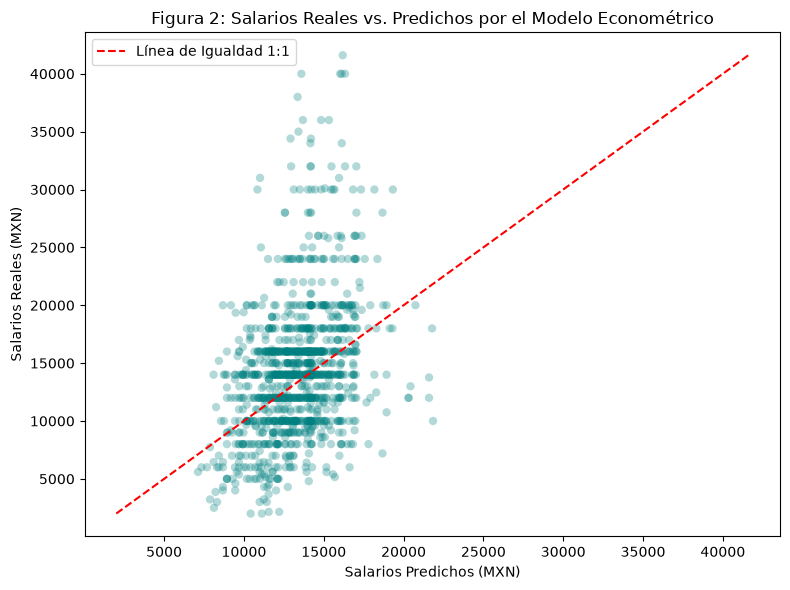

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(salarios_predichos, salarios_reales, alpha=0.3, color='teal', edgecolors='none')
plt.plot([min(salarios_reales), max(salarios_reales)], [min(salarios_reales), max(salarios_reales)], color='red', linestyle='--', label='Línea de Igualdad 1:1')
plt.title('Figura 2: Salarios Reales vs. Predichos por el Modelo Econométrico')
plt.xlabel('Salarios Predichos (MXN)')
plt.ylabel('Salarios Reales (MXN)')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/pareada_real_vs_pred.png', dpi=300)
plt.show()